# Project 3 - Step 5 (civil model): Pedestrian bridge - threshold, smoothing, STL export, check

Input: the two optimized bridges from `Step3_Bridge_STL_Voxel_TO.ipynb` (saved in `results/`):
- **A: pinned - pinned** (inclined legs, horizontal thrust)
- **B: pinned - roller** (vertical legs + tie)

Post-processing (same core function as Step 5, `topopt3d.smooth_surface`):
threshold → remove floating islands → marching cubes → Taubin smoothing → STL.

Extra check for a structure: **does the exported, smoothed part still carry the load as well as the
optimized design?** The exported STL is voxelized again, given the same supports and deck load, and analysed.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

from topopt3d import (VoxelMesh, BoundaryConditions, FEModel, smooth_surface, write_stl, read_stl,
                      stl_volume)

pv.global_theme.background = "white"
STL = "sample_parts/pedestrian_bridge.stl"
mesh = VoxelMesh.from_stl(STL, resolution=60)
cases = {"A: pinned - pinned": ("results/bridge_caseA_x.npy", "xyz"),
         "B: pinned - roller": ("results/bridge_caseB_x.npy", "yz")}
x = {}
for name, (path, _) in cases.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} missing: run Step3_Bridge_STL_Voxel_TO.ipynb first")
    x[name] = np.load(path)
part_volume = mesh.n_elem * np.prod(mesh.size)
print(mesh)
for name, xi in x.items():
    print(f"{name}: {np.mean(xi > 0.9):.0%} of voxels > 0.9, {np.mean(xi < 0.1):.0%} < 0.1, "
          f"{np.mean((xi >= 0.1) & (xi <= 0.9)):.0%} gray")


def render(tri, title="", camera="iso", window=(1000, 520), zoom=1.3):
    t = np.asarray(tri).reshape(-1, 3)
    n = len(t) // 3
    surf = pv.PolyData(t, np.column_stack([np.full(n, 3), np.arange(3 * n).reshape(n, 3)]).ravel()).clean()
    p = pv.Plotter(off_screen=True, window_size=window)
    p.add_mesh(surf, color="#4d8fd6", smooth_shading=True, specular=0.3)
    if camera == "below":
        p.view_vector((-1, -1, -0.6))
    elif camera == "elevation":
        p.view_xz()
    else:
        p.camera_position = camera
    p.camera.zoom(zoom)
    img = p.screenshot(return_img=True)
    p.close()
    return img


def show_row(images, titles, size=(18, 4.2)):
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, img, t in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()
    return fig

VoxelMesh(grid 60 x 8 x 20, voxel [2.0, 2.0, 2.0], 6720 elements, 8370 nodes, 25110 DOFs)
A: pinned - pinned: 23% of voxels > 0.9, 61% < 0.1, 15% gray
B: pinned - roller: 24% of voxels > 0.9, 59% < 0.1, 17% gray


## 1. Threshold (case A)
The deck is always solid (kept region), so the threshold only changes the legs and struts.

threshold solid voxels    volume % of domain islands removed closed
      0.3         2148     17349       32.3%               0 True


      0.5         1916     14593       27.1%               0 True


      0.7         1744     11222       20.9%               0 True


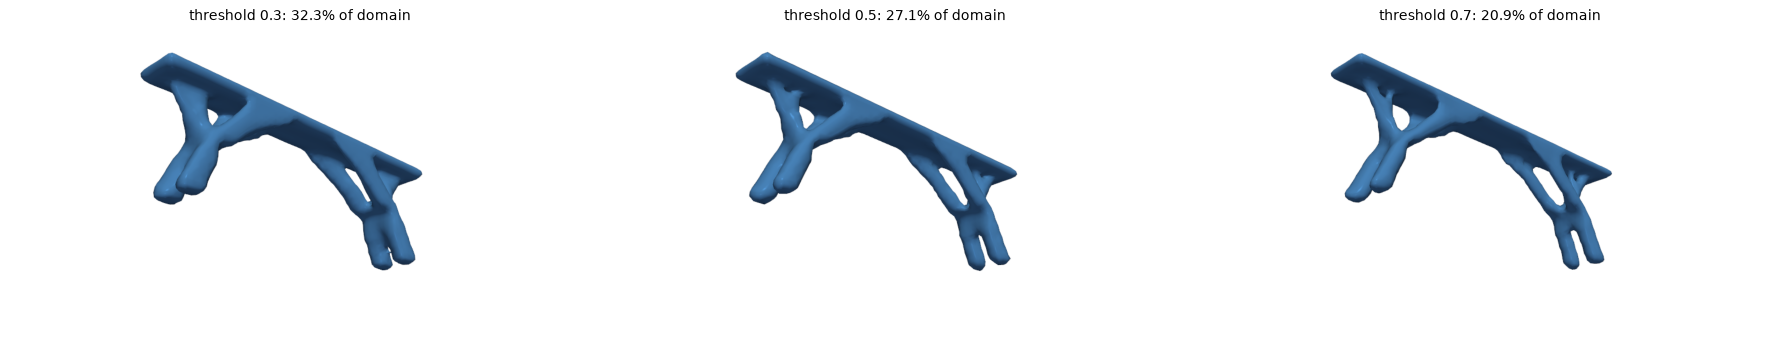

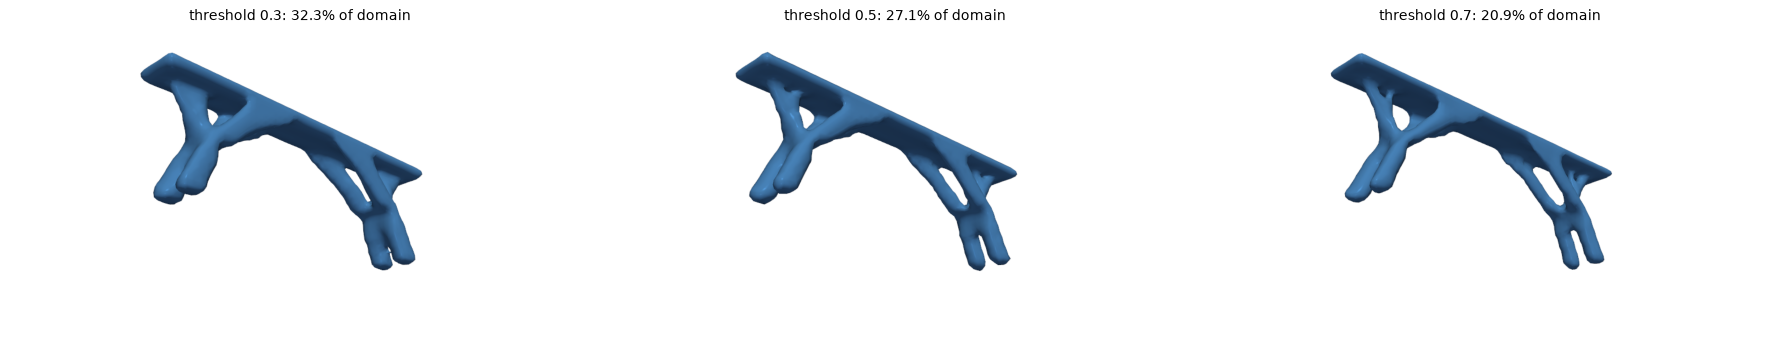

In [2]:
xa = x["A: pinned - pinned"]
imgs, titles = [], []
print(f"{'threshold':>9s} {'solid voxels':>12s} {'volume':>9s} {'% of domain':>11s} {'islands removed':>15s} closed")
for t in (0.3, 0.5, 0.7):
    tri, info = smooth_surface(mesh, xa, threshold=t)
    print(f"{t:9.1f} {info['solid_voxels']:12d} {info['volume']:9.0f} {100 * info['volume'] / part_volume:10.1f}% "
          f"{info['islands_removed']:15d} {info['watertight']}")
    imgs.append(render(tri, camera="below")); titles.append(f"threshold {t}: {100 * info['volume'] / part_volume:.1f}% of domain")
show_row(imgs, titles)

## 2. Smoothing method (case A, threshold 0.5)
Plain Laplacian smoothing shrinks thin parts; here it would thin the 4-unit deck and the legs.

method                   volume  vs raw deck top z
raw marching cubes        14924   +0.0%      40.00


Laplacian 20              11012  -26.2%      40.00


Taubin 20                 14593   -2.2%      40.00


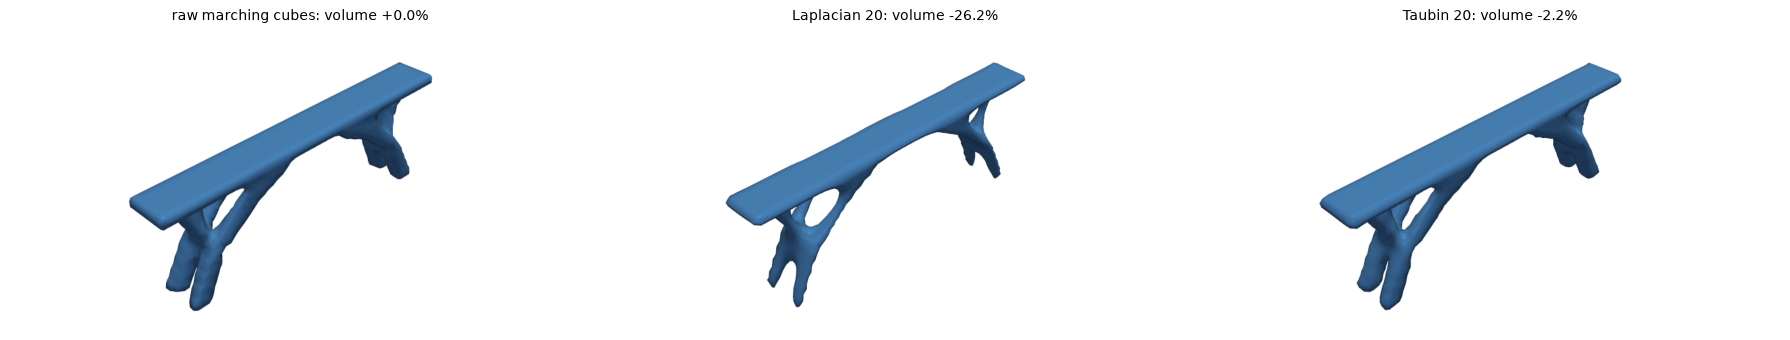

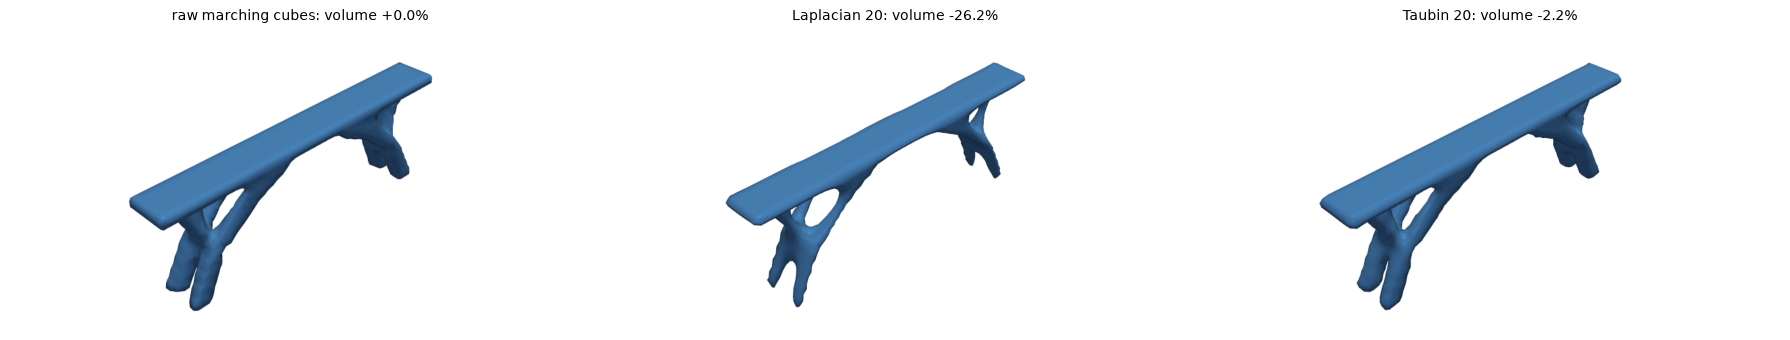

In [3]:
imgs, titles = [], []
raw = None
print(f"{'method':22s} {'volume':>8s} {'vs raw':>7s} {'deck top z':>10s}")
for method, it, label in [("none", 0, "raw marching cubes"), ("laplacian", 20, "Laplacian 20"),
                          ("taubin", 20, "Taubin 20")]:
    tri, info = smooth_surface(mesh, xa, threshold=0.5, iterations=it, method=method)
    raw = raw or info["volume"]
    top = np.percentile(tri[:, :, 2], 99)          # height of the deck surface
    print(f"{label:22s} {info['volume']:8.0f} {100 * (info['volume'] / raw - 1):+6.1f}% {top:10.2f}")
    imgs.append(render(tri)); titles.append(f"{label}: volume {100 * (info['volume'] / raw - 1):+.1f}%")
show_row(imgs, titles)

**Decision (same as Step 5):** Taubin, 20 iterations, threshold 0.5, no pre-blur, and **outer faces kept flat**
(`flat_bounds=True`, new for the bridge, see section 4): vertices on the 6 outer planes of the design domain
(abutment bases, deck top, ends, sides) may slide along the plane but not leave it, and nothing leaves the domain.

Taubin, free smoothing        : lowest z = -0.43 (ground = 0), highest z = 40.31 (deck top = 40)


Taubin, outer faces kept flat : lowest z = +0.00 (ground = 0), highest z = 40.00 (deck top = 40)


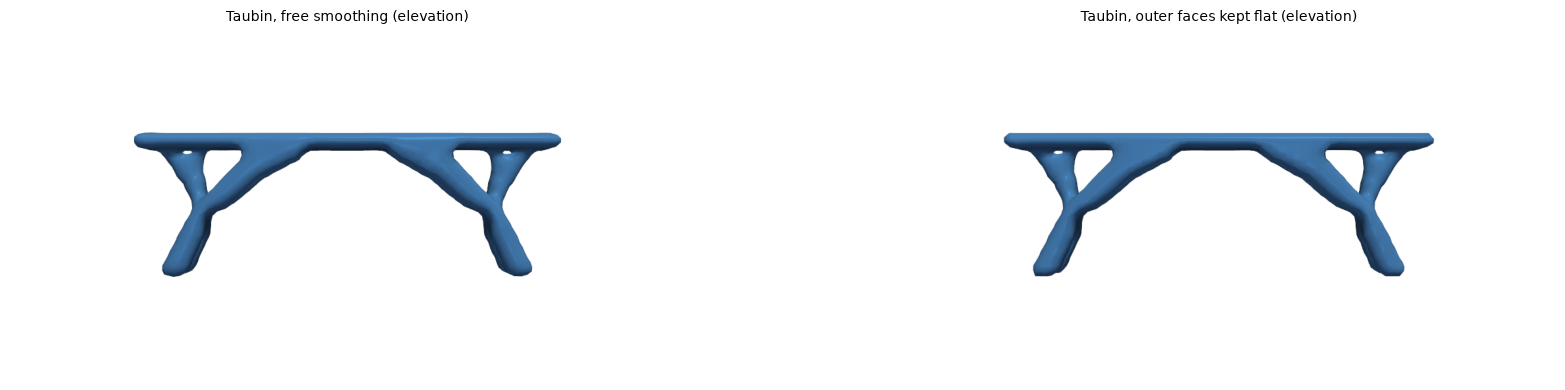

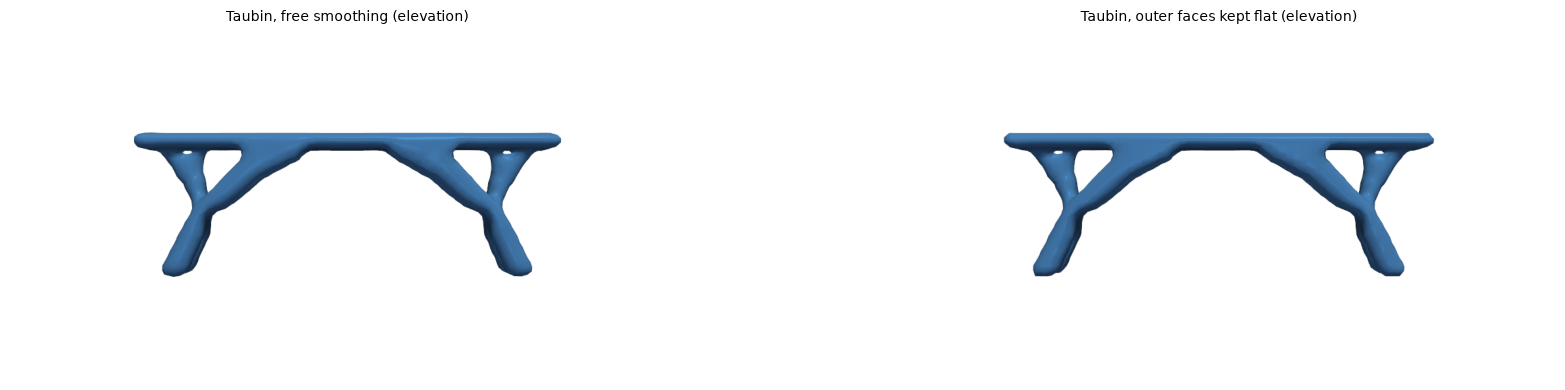

In [4]:
imgs, titles = [], []
for flat, label in [(False, "Taubin, free smoothing"), (True, "Taubin, outer faces kept flat")]:
    tri, info = smooth_surface(mesh, xa, threshold=0.5, iterations=20, flat_bounds=flat)
    zmin, zmax = tri[:, :, 2].min(), tri[:, :, 2].max()
    print(f"{label:30s}: lowest z = {zmin:+.2f} (ground = 0), highest z = {zmax:.2f} (deck top = 40)")
    imgs.append(render(tri, camera="elevation")); titles.append(f"{label} (elevation)")
show_row(imgs, titles, size=(18, 4))

## 3. Export both bridges as STL

In [5]:
os.makedirs("results", exist_ok=True)
exported = {}
for name in cases:
    tri, info = smooth_surface(mesh, x[name], threshold=0.5, iterations=20, method="taubin")
    path = f"results/bridge_{name[0]}_{name[3:].replace(' - ', '_').replace(' ', '_')}.stl"
    write_stl(path, tri)
    back = read_stl(path)
    faces = np.arange(3 * len(back)).reshape(-1, 3)
    welded = pv.PolyData(back.reshape(-1, 3), np.column_stack([np.full(len(back), 3), faces]).ravel()).clean()
    open_edges = welded.extract_feature_edges(boundary_edges=True, feature_edges=False,
                                              manifold_edges=False, non_manifold_edges=False).n_cells
    exported[name] = path
    print(f"{path}: {len(back)} triangles, {os.path.getsize(path) / 1024:.0f} kB, volume {stl_volume(back):.0f} "
          f"({100 * stl_volume(back) / part_volume:.1f}% of domain), open edges {open_edges}, "
          f"islands removed {info['islands_removed']}")

results/bridge_A_pinned_pinned.stl: 5644 triangles, 276 kB, volume 14593 (27.1% of domain), open edges 0, islands removed 0
results/bridge_B_pinned_roller.stl: 6428 triangles, 314 kB, volume 13477 (25.1% of domain), open edges 0, islands removed 0


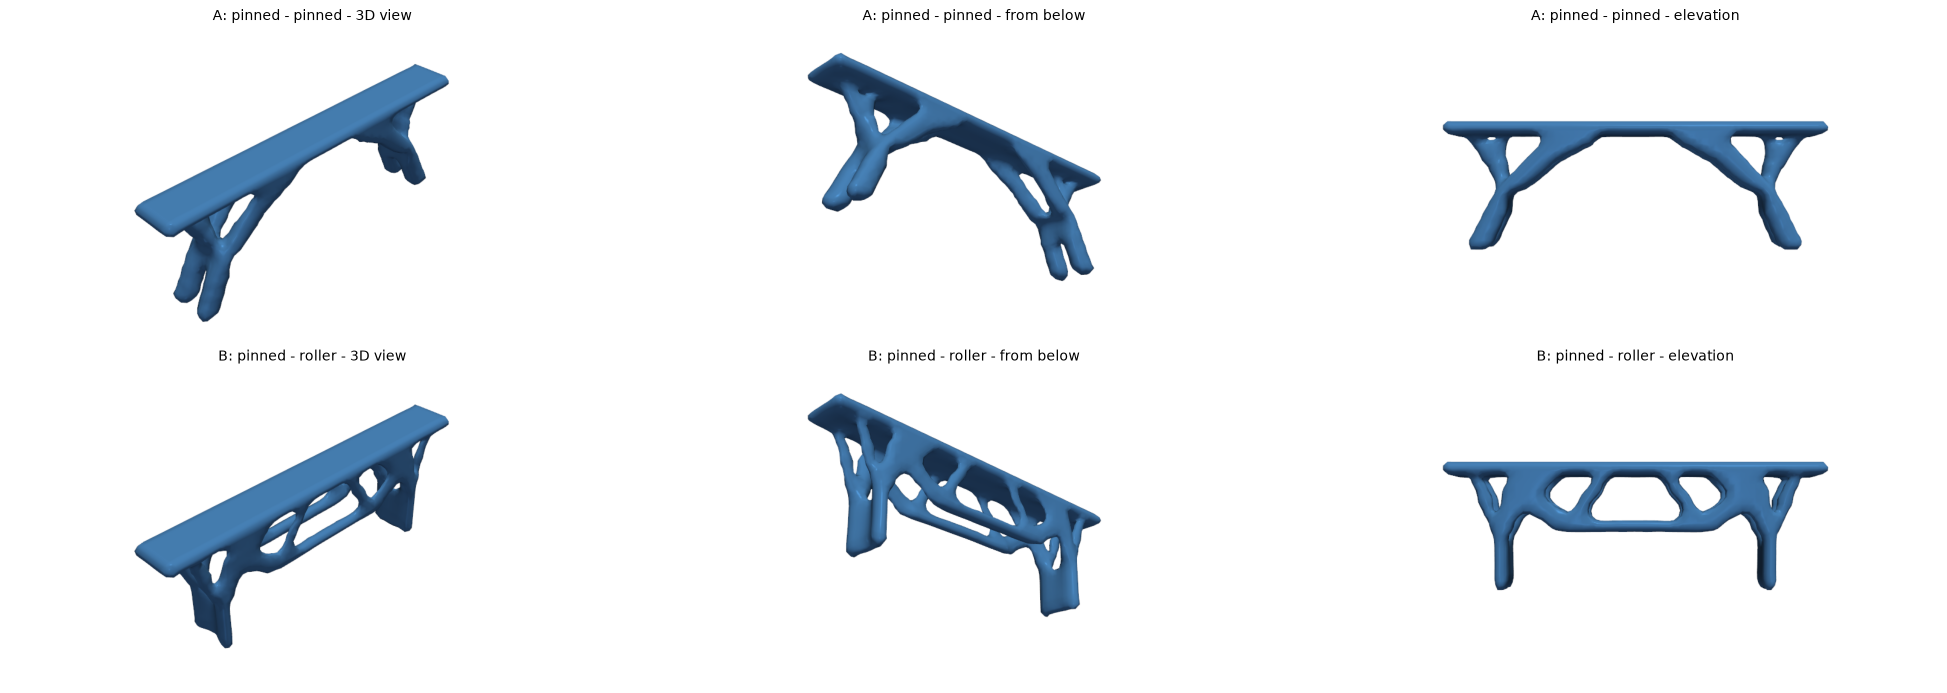

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(20, 7))
for row, name in zip(axes, cases):
    back = read_stl(exported[name])
    for ax, cam, label in zip(row, ("iso", "below", "elevation"), ("3D view", "from below", "elevation")):
        ax.imshow(render(back, camera=cam)); ax.set_title(f"{name} - {label}", fontsize=10); ax.axis("off")
plt.tight_layout()
plt.savefig("results/bridge_A_vs_B_exported.png", dpi=130)
plt.show()

## 4. Does the exported part still work? (structural check)
Three models of each bridge, all with the same supports (abutment bases) and the same total deck load:
1. **Optimized design** - gray densities with SIMP penalty (what the optimizer minimized)
2. **Black/white design** - voxels with density ≥ 0.5 solid, the rest (almost) empty
3. **Exported STL** - the smoothed surface voxelized again at the same voxel size (2) and analysed as solid,
   once with **free** smoothing and once with the **outer faces kept flat** (final export)

Compliance c = Fᵀu (lower = stiffer). Same E = 1, ν = 0.25.

*Finding while building this check:* with free smoothing, the rounded abutment feet touched the ground with only
4-10 nodes instead of 99 and reached 1 unit below the ground; the roller bridge (B) then became almost a mechanism.
That is why `flat_bounds=True` was added to the core.

In [7]:
def bridge_bc(m, right_dirs, solid=None):
    """Supports at the lowest nodes of EACH abutment (after smoothing the two bases need not be at
    exactly the same height), load on the highest (deck) nodes, total (0, 0, -1)."""
    nodes = m.surface_nodes()
    if solid is not None:                       # only nodes of solid elements
        nodes = np.intersect1d(nodes, np.unique(m.elements[solid]))
    x_, z_ = m.nodes[nodes, 0], m.nodes[nodes, 2]
    bc = BoundaryConditions(m)
    counts = []
    for side, dirs in ((x_ <= 20 + 1e-6, "xyz"), (x_ >= 100 - 1e-6, right_dirs)):
        base = nodes[side & (z_ < z_[side].min() + 1e-6)]
        bc.fix(base, dirs)
        counts.append(len(base))
    bc.load(nodes[z_ > z_.max() - 1e-6], (0, 0, -1))
    bc.support_counts = counts
    return bc


def compliance(m, bc, dens, penal):
    fe = FEModel(m, 1.0, 0.25)
    u = fe.solve(fe.assemble(dens, penal), bc)
    return float(bc.forces @ u)


import tempfile


def stl_check(stl_path, right_dirs):
    m2 = VoxelMesh.from_stl(stl_path, voxel_size=2.0)
    bc2 = bridge_bc(m2, right_dirs)
    lowest = min(m2.nodes[bc2.supports[0][0], 2].min(), m2.nodes[bc2.supports[1][0], 2].min())
    return compliance(m2, bc2, np.ones(m2.n_elem), 1), m2.n_elem * 8, bc2.support_counts, lowest


rows = []
tmp = tempfile.mkdtemp()
for name, (_, right_dirs) in cases.items():
    xi = x[name]
    c_opt = compliance(mesh, bridge_bc(mesh, right_dirs), xi, 3)
    binary = np.where(xi >= 0.5, 1.0, 1e-3)
    bw_bc = bridge_bc(mesh, right_dirs, solid=xi >= 0.5)
    c_bw = compliance(mesh, bw_bc, binary, 1)
    free_path = os.path.join(tmp, "free.stl")
    write_stl(free_path, smooth_surface(mesh, xi, threshold=0.5, iterations=20, flat_bounds=False)[0])
    c_free, v_free, n_free, z_free = stl_check(free_path, right_dirs)
    c_flat, v_flat, n_flat, z_flat = stl_check(exported[name], right_dirs)
    print(f"{name}: support nodes left/right: black/white {bw_bc.support_counts}, "
          f"STL free smoothing {n_free} (base at z = {z_free:+.2f}), "
          f"STL flat faces {n_flat} (base at z = {z_flat:+.2f})")
    rows.append((name, c_opt, c_bw, c_free, c_flat, (xi >= 0.5).sum() * 8, v_free, v_flat))

print(f"\n{'case':20s} {'optimized':>10s} {'black/white':>11s} {'STL free':>9s} {'STL flat':>9s}  "
      f"{'V b/w':>6s} {'V free':>6s} {'V flat':>6s}")
for name, c1, c2, c3, c4, v2, v3, v4 in rows:
    print(f"{name:20s} {c1:10.4f} {c2:11.4f} {c3:9.4f} {c4:9.4f}  {v2:6.0f} {v3:6.0f} {v4:6.0f}")
print()
for name, c1, c2, c3, c4, v2, v3, v4 in rows:
    print(f"{name}: final STL (flat faces) is {100 * (c4 / c2 - 1):+.1f}% vs black/white "
          f"(volume {100 * (v4 / v2 - 1):+.1f}%); free smoothing was {100 * (c3 / c2 - 1):+.1f}%")
cA, cB = rows[0][4], rows[1][4]
print(f"Final exported bridges: B is {100 * (cB / cA - 1):.0f}% more flexible than A (optimizer: 31%)")

A: pinned - pinned: support nodes left/right: black/white [30, 30], STL free smoothing [10, 10] (base at z = -1.06), STL flat faces [29, 30] (base at z = +0.00)


B: pinned - roller: support nodes left/right: black/white [24, 24], STL free smoothing [4, 4] (base at z = -0.88), STL flat faces [22, 22] (base at z = +0.00)

case                  optimized black/white  STL free  STL flat   V b/w V free V flat
A: pinned - pinned       0.6443      0.5541    0.7480    0.5832   15328  16768  15000
B: pinned - roller       0.8458      0.7785   29.4477    0.7975   14464  14152  14680

A: pinned - pinned: final STL (flat faces) is +5.3% vs black/white (volume -2.1%); free smoothing was +35.0%
B: pinned - roller: final STL (flat faces) is +2.4% vs black/white (volume +1.5%); free smoothing was +3682.7%
Final exported bridges: B is 37% more flexible than A (optimizer: 31%)


## 5. Summary
- Final bridges exported as closed STL files: `results/bridge_A_pinned_pinned.stl`, `results/bridge_B_pinned_roller.stl`
  and a comparison picture `results/bridge_A_vs_B_exported.png`.
- Taubin smoothing keeps the volume and the deck thickness; Laplacian smoothing shrinks the part.
- **Smoothing must not touch the supports:** free smoothing rounded the abutment feet (99 → 4-10 contact nodes),
  pushed them below the ground and made the roller bridge nearly a mechanism. Keeping the outer faces flat fixes it.
- The structural check shows how much stiffness changes from the optimized (gray) design to the black/white
  design and to the smoothed, exported part, and whether the A vs B difference survives post-processing.